In [2]:
import matplotlib
import matplotlib.pyplot as plt

matplotlib.use("pgf")
plt.style.use('default')
matplotlib.rcParams.update({
	"pgf.texsystem": "pdflatex",
	'font.family': 'sans-serif',
	'text.usetex': True,
	'pgf.rcfonts': False,
	'savefig.bbox': 'tight',
	'savefig.pad_inches': 0.0,
})

In [3]:
import numpy as np
from matplotlib import pyplot as plt
from coons import *

%load_ext autoreload
%autoreload 2

In [4]:
plt.style.use('default')
# plt.rcParams['figure.dpi'] = 300

In [7]:
mask = np.ones((3,3))
mask[1,1] = -1
A = coons(np.ones((10,10)), mask)
plt.imshow(A == 0, cmap="gray")
plt.savefig("img/matrix.pgf")

In [15]:
def construct_example(m=11, n=9):
	phi = np.linspace(-np.pi/2, np.pi/2, m)
	theta = np.linspace(-np.pi/2, np.pi/2, n)

	P = np.full((m, n, 3), np.nan)
	P[:,0,:] = np.array((-1-np.cos(phi), np.sin(phi), np.zeros(m))).T # left
	P[:,-1,:] = np.array((1+np.cos(phi), np.sin(phi), np.zeros(m))).T # right
	P[0,:,:] = np.array((np.sin(theta), -np.ones(n), np.cos(theta))).T # top
	P[-1,:,:] = np.array((np.sin(theta), np.ones(n), np.cos(theta))).T # bottom
	return P

P = construct_example()
ax = plt.figure().add_subplot(projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2])
ax.set(zlim=(0,2))
ax.set_aspect('equal')

Text(0.5, 0.92, '$\\alpha = 0$')

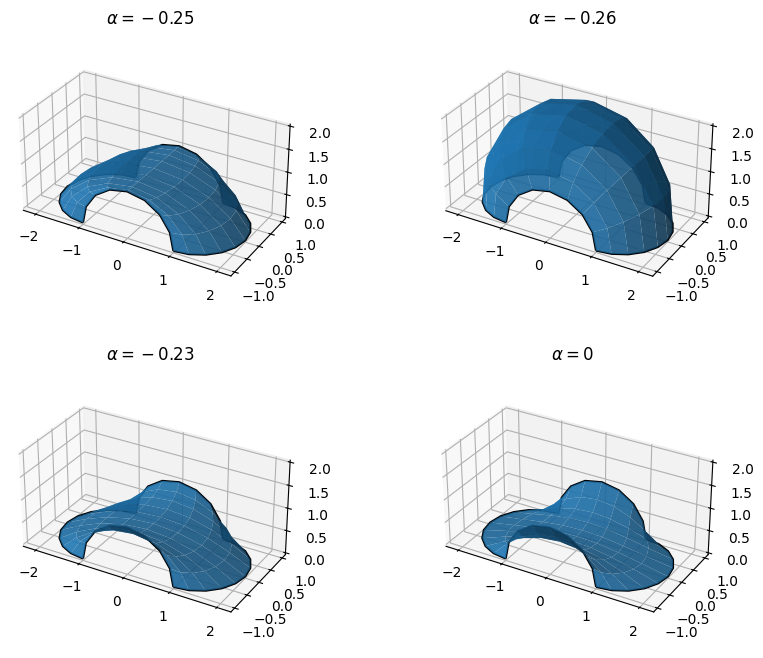

In [4]:
P_25 = coons3(P.copy(), construct_mask(-0.25))
P_26 = coons3(P.copy(), construct_mask(-0.26))
P_23 = coons3(P.copy(), construct_mask(-0.23))
P_0 = coons3(P.copy(), construct_mask(0))

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(221, projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2], color='black')
ax.plot_surface(P_25[:,:,0], P_25[:,:,1], P_25[:,:,2], color='tab:blue', alpha=0.9)
ax.set(zlim=(0,2))
ax.set_aspect('equal')
plt.title("$\\alpha = -0.25$")

ax = fig.add_subplot(222, projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2], color='black')
ax.plot_surface(P_26[:,:,0], P_26[:,:,1], P_26[:,:,2], color='tab:blue', alpha=0.9)
ax.set(zlim=(0,2))
ax.set_aspect('equal')
plt.title("$\\alpha = -0.26$")

ax = fig.add_subplot(223, projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2], color='black')
ax.plot_surface(P_23[:,:,0], P_23[:,:,1], P_23[:,:,2], color='tab:blue', alpha=0.9)
ax.set(zlim=(0,2))
ax.set_aspect('equal')
plt.title("$\\alpha = -0.23$")

ax = fig.add_subplot(224, projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2], color='black')
ax.plot_surface(P_0[:,:,0], P_0[:,:,1], P_0[:,:,2], color='tab:blue', alpha=0.9)
ax.set(zlim=(0,2))
ax.set_aspect('equal')
plt.title("$\\alpha = 0$")

# fig.savefig('img/example.pgf')

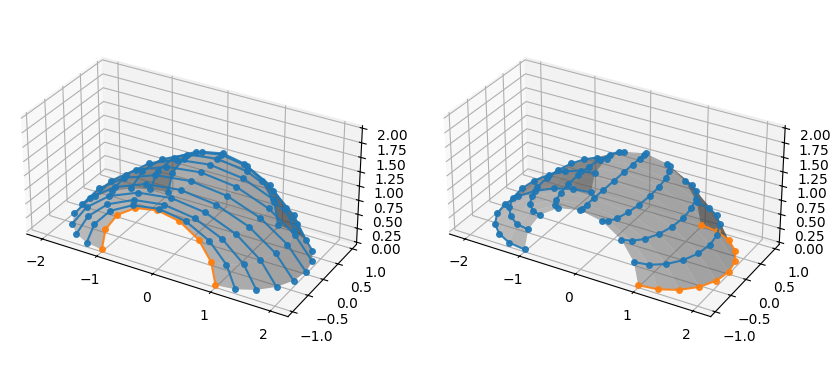

In [5]:
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(121, projection='3d')
ax.plot_surface(P_25[:,:,0], P_25[:,:,1], P_25[:,:,2], color='tab:gray', alpha=0.5, zorder=3)
ax.plot(P_25[0,:,0], P_25[0,:,1], P_25[0,:,2], '-o', color='tab:orange', alpha=0.9, zorder=3, markersize=4)
for i in range(1, P.shape[0]):
	ax.plot(P_25[i,:,0], P_25[i,:,1], P_25[i,:,2], '-o', color='tab:blue', alpha=0.9, zorder=3, markersize=4)
ax.set(zlim=(0,2))
ax.set_aspect('equal')

ax = fig.add_subplot(122, projection='3d')
ax.plot_surface(P_25[:,:,0], P_25[:,:,1], P_25[:,:,2], color='tab:gray', alpha=0.5, zorder=3)
ax.plot(P_25[:,-1,0], P_25[:,-1,1], P_25[:,-1,2], '-o', color='tab:orange', alpha=0.9, zorder=3, markersize=4)
for i in range(0, P.shape[1]-1):
	ax.plot(P_25[:,i,0], P_25[:,i,1], P_25[:,i,2], '-o', color='tab:blue', alpha=0.9, zorder=3, markersize=4)
ax.set(zlim=(0,2))
ax.set_aspect('equal')

# plt.savefig('img/error.pgf')

In [18]:
def construct_example2(m=11, n=9):
	phi = np.linspace(-np.pi/2, np.pi/2, m)
	theta = np.linspace(-np.pi/2, np.pi/2, n)

	P = np.full((m, n, 3), np.nan)
	P[:,0,:] = np.array((-1+np.cos(phi), np.sin(phi), np.zeros(m))).T # left
	P[:,-1,:] = np.array((1-np.cos(phi), np.sin(phi), np.zeros(m))).T # right
	P[0,:,:] = np.array((np.sin(theta), -np.ones(n), np.cos(theta))).T # top
	P[-1,:,:] = np.array((np.sin(theta), np.ones(n), np.cos(theta))).T # bottom
	return P

P = construct_example2()

In [19]:
best_alpha, alphas, err = optimize_alpha(P.copy())
print(f"{best_alpha = }")

plt.figure()
plt.plot(alphas, err)
plt.yscale('log')
plt.xlabel("$\\alpha$")
plt.ylabel("Napaka")

plt.savefig("img/opt2_alpha.pgf")

best_alpha = -0.15715715715715717


In [20]:
P_coons = coons3(P.copy(), construct_mask(-0.25))

P_opt = coons3(P.copy(), construct_mask(best_alpha))

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(121, projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2], color='black')
ax.plot_surface(P_coons[:,:,0], P_coons[:,:,1], P_coons[:,:,2], color='tab:blue', alpha=0.9)
ax.set_aspect('equal')
ax.set_title("$\\alpha = -0.25\\ (Coons)$")

ax = fig.add_subplot(122, projection='3d')
ax.plot_wireframe(P[:,:,0], P[:,:,1], P[:,:,2], color='black')
ax.plot_surface(P_opt[:,:,0], P_opt[:,:,1], P_opt[:,:,2], color='tab:blue', alpha=0.9)
ax.set_aspect('equal')
ax.set_title(f"$\\alpha = {best_alpha:0.4f}\\ (optimizirana)$")

plt.savefig("img/opt2_cmp.pgf")

In [7]:
def coons_system(mask: np.ndarray, n: int, m: int):
    unknowns = (n-2)*(m-2)
    A = np.zeros((unknowns, unknowns))

    cell_to_col = lambda i, j: (i-1)*(n-2) + (j-1)

    for i, j in product(range(1,m-1), range(1,n-1)):
        for x, y in product(range(-1, 2), repeat=2):
            k = mask[y+1, x+1]
            if 0 < i+y < m-1 and 0 < j+x < n-1:
                A[cell_to_col(i, j)][cell_to_col(i+y, j+x)] += k
    
    return A

In [13]:
plt.figure(figsize=(10,10))
for i, n in enumerate(range(3,12)):
	plt.subplot(3, 3, i+1)
	determinants = []
	aa = np.linspace(-1, 1, 1000)
	for a in aa:
		A = coons_system(construct_mask(a), n, n)
		determinants.append(np.linalg.det(A))

	det = np.array(determinants)
	plt.plot(aa, det)
	plt.yscale('symlog', linthresh=1e-12)
	plt.axhline(0, linestyle='--')
	plt.axvline(0, linestyle='--')
	plt.axvline(-1/4, linestyle='--')
	plt.title(f"n=m={n}")

plt.savefig("img/determinants.pgf")

In [14]:
plt.figure(figsize=(10,10))
for i, n in enumerate(range(3,12)):
	plt.subplot(3, 3, i+1)
	conditions = []
	aa = np.linspace(-1, 1, 1000)
	for a in aa:
		A = coons_system(construct_mask(a), n, n)
		conditions.append(np.linalg.cond(A))

	det = np.array(conditions)
	plt.plot(aa, det)
	plt.yscale('log')
	plt.ylim((0,1e9))
	plt.axhline(0, linestyle='--')
	plt.axvline(0, linestyle='--')
	plt.axvline(-1/4, linestyle='--')
	plt.title(f"n=m={n}")

plt.savefig("img/conditions.pgf")

C:\Users\jezersek\AppData\Local\Temp\ipykernel_10864\3211510135.py:13: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim((0,1e9))
